# 02 — VGG16 Transfer Öğrenmesi ile Sınıflandırma

Akciğer BT kesitlerini **normal / anormal** olarak sınıflandıran ilk yaklaşım.
ImageNet üzerinde eğitilmiş VGG16 gövdesi dondurulur ve üzerine yalnızca tam bağlı
katmanlardan oluşan bir başlık eklenir (*transfer learning*).

Bu notebook'ta altı farklı başlık/giriş varyantı karşılaştırılmıştır. Dağıtılan
sınıflandırıcı (InceptionV3 tabanlı `model_in_5_1.h5`) bu notebook'tan değil, `03`
numaralı notebook'tan gelir; buradaki modeller karşılaştırma/deneme amaçlıdır.

## Varyantlar

| Ad | Giriş | Başlık | Kayıp | Epoch | Not |
|----|-------|--------|-------|-------|-----|
| `model1` | 224² | Flatten → Dense(512, relu) → Dense(2, softmax) | categorical | 100 | temel model |
| `model1_1_a` | 224² | `model1` ile aynı | categorical | 100 | aynı mimarinin tekrarı |
| `model2` | 224² | Flatten → Dropout(0.2) → Dense(6272, relu) → Dense(1, sigmoid) | binary | 100 | çok geniş ara katman |
| `model2_a` | 224² | Flatten → Dropout(0.2) → Dense(8192, relu) → Dense(1, sigmoid) | binary | 200 | daha geniş, daha uzun |
| `model3` | 224² | Flatten → Dense(256, relu) → Dense(512, relu) → Dense(1, sigmoid) | binary | 100 | iki katmanlı hafif başlık |
| `model4` | 224² | `model3` ile aynı + veri artırma | binary | 100 | augmentation denemesi |

> **Önceki sürümdeki hata:** `model4` için veri artırma üreteci tanımlanmış, ancak
> eğitimde artırmasız üreteç kullanılmıştı; yani `model3` ile `model4` fiilen aynı
> deneydi. Bu sürümde `model4` gerçekten artırılmış üreteci kullanır.


## 1. Ortam


In [ ]:
# Colab kullanıyorsanız:
# from google.colab import drive
# drive.mount("/content/drive")
# !unzip -q /content/drive/MyDrive/png.zip

import os
import random
import shutil

import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.applications import VGG16
from tensorflow.keras.optimizers import RMSprop
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.preprocessing.image import ImageDataGenerator

# ---------------------------------------------------------------- yollar
DATA_ROOT = "/content/drive/MyDrive/lungscan"
SPLIT_DIR = os.path.join(DATA_ROOT, "classification")      # train/ ve test/ alt klasörleri
MODELS_DIR = os.path.join(DATA_ROOT, "models")
for _d in (SPLIT_DIR, MODELS_DIR):
    os.makedirs(_d, exist_ok=True)

# ------------------------------------------------------------- parametreler
TEST_RATIO = 0.2
SEED = 42
INPUT_SIZE = (224, 224)
BATCH_SIZE = 64
print("TensorFlow:", tf.__version__)


## 2. Sınıflandırma veri kümesinin hazırlanması

Kaynak klasörler `normal/` ve `abnormal/` olarak ayrılmıştır. Dosyalar
`classification/{train,test}/{normal,abnormal}` düzenine kopyalanır.

> **Önceki sürümdeki hatalar:** `os.makedirs` `exist_ok` olmadan çağrıldığı için
> notebook ikinci kez çalıştırıldığında hata veriyordu ve iki sınıf birbirinden
> bağımsız bölündüğü için sınıf oranları kayıyordu. Bu sürümde tek bir dizin listesi
> bölünür ve kopyalama idempotenttir.


In [ ]:
def prepare_classification_split(source_dir, split_dir, test_ratio=0.2, seed=42):
    """`normal/` ve `abnormal/` klasörlerini train/test olarak kopyalar.

    Bölme, sınıf etiketiyle birlikte tek bir dosya listesi üzerinden yapılır; böylece
    her sınıf aynı oranda temsil edilir ve tekrar çalıştırılabilir.
    """
    class_names = ("abnormal", "normal")

    for split in ("train", "test"):
        for name in class_names:
            os.makedirs(os.path.join(split_dir, split, name), exist_ok=True)

    total = 0
    for name in class_names:
        files = sorted(f for f in os.listdir(os.path.join(source_dir, name)) if f.endswith(".png"))
        train_files, test_files = train_test_split(
            files, test_size=test_ratio, random_state=seed, shuffle=True
        )
        for split, items in (("train", train_files), ("test", test_files)):
            for filename in items:
                shutil.copy(
                    os.path.join(source_dir, name, filename),
                    os.path.join(split_dir, split, name, filename),
                )
        print(f"{name:>8}: {len(train_files)} eğitim | {len(test_files)} test")
        total += len(files)

    print(f"Toplam {total} görüntü -> {split_dir}")
    return split_dir


# Kaynak: veri hazırlama adımında PNG'ye çevrilmiş tüm kesitler
SOURCE_DIR = "/content/all"
prepare_classification_split(SOURCE_DIR, SPLIT_DIR, test_ratio=TEST_RATIO, seed=SEED)


In [ ]:
for split in ("train", "test"):
    print(f"--- {split}")
    for name in ("normal", "abnormal"):
        path = os.path.join(SPLIT_DIR, split, name)
        print(f"    {name:>8}: {len(os.listdir(path)):>4} görüntü")


## 3. Veri üreteçleri


In [ ]:
train_datagen = ImageDataGenerator(rescale=1.0 / 255)
eval_datagen = ImageDataGenerator(rescale=1.0 / 255)

# Yalnızca `model4` varyantı için: hafif veri artırma
augment_datagen = ImageDataGenerator(
    rescale=1.0 / 255,
    rotation_range=20,
    width_shift_range=0.2,
    height_shift_range=0.2,
    shear_range=0.2,
    zoom_range=0.2,
    horizontal_flip=True,
)


def make_generator(datagen, directory, class_mode, shuffle, input_size=INPUT_SIZE):
    """Belirtilen klasörden akış üreteci oluşturur.

    Not: doğrulama üreteci `shuffle=False` olmalıdır; aksi hâlde `generator.classes`
    ile tahminlerin sırası eşleşmez ve metrikler geçersiz olur.
    """
    return datagen.flow_from_directory(
        directory,
        target_size=input_size,
        batch_size=BATCH_SIZE,
        class_mode=class_mode,
        shuffle=shuffle,
    )


train_cat = make_generator(train_datagen, os.path.join(SPLIT_DIR, "train"), "categorical", True)
test_cat = make_generator(eval_datagen, os.path.join(SPLIT_DIR, "test"), "categorical", False)

train_bin = make_generator(train_datagen, os.path.join(SPLIT_DIR, "train"), "binary", True)
test_bin = make_generator(eval_datagen, os.path.join(SPLIT_DIR, "test"), "binary", False)

train_aug = make_generator(augment_datagen, os.path.join(SPLIT_DIR, "train"), "binary", True)

print("Sınıf indeksleri:", train_cat.class_indices)


## 4. Görsel doğrulama

Eğitim kümesinden rastgele altı kesit ve etiketleri.


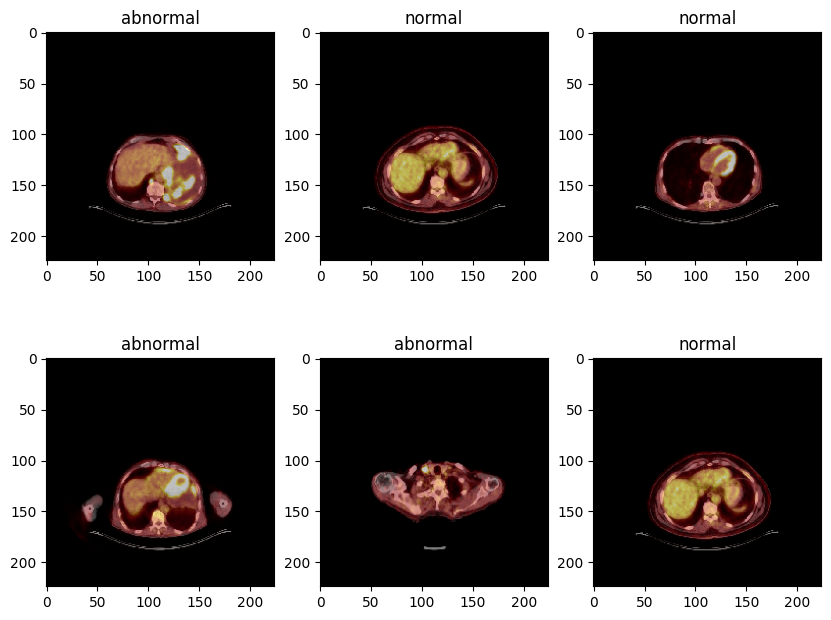

In [ ]:
titles = {index: name for name, index in train_cat.class_indices.items()}

sample_images, sample_labels = next(train_cat)
sample_labels = np.argmax(sample_labels, axis=1)

plt.figure(figsize=(10, 12))
for i in range(6):
    ax = plt.subplot(3, 3, i + 1)
    index = random.choice(range(len(sample_images)))
    plt.imshow(sample_images[index], cmap=plt.cm.binary)
    plt.title(titles[int(sample_labels[index])])
    plt.axis("off")
plt.tight_layout()
plt.show()


## 5. VGG16 gövdesi ve sınıflandırma başlığı

Gövde dondurulur (`trainable = False`); yalnızca başlık eğitilir. Bu, küçük veri
kümelerinde aşırı öğrenmeyi (overfitting) azaltır ve eğitimi hızlandırır.


In [ ]:
def build_vgg16_backbone(input_size=(224, 224, 3)):
    """ImageNet ağırlıklı, sınıflandırma katmanları çıkarılmış ve dondurulmuş VGG16."""
    backbone = VGG16(weights="imagenet", include_top=False, input_shape=input_size)
    backbone.trainable = False
    return backbone


def build_classifier(backbone, head="softmax", dense=512, dropout=0.0):
    """Dondurulmuş gövde üzerine tam bağlı sınıflandırma başlığı ekler.

    Args:
        head:    "softmax" → 2 nöronlu softmax çıkışı (categorical kayıp)
                 "sigmoid" → 1 nöronlu sigmoid çıkışı (binary kayıp)
        dense:   Ara katman nöron sayısı ya da nöron sayılarının listesi.
        dropout: Ara katman(lar)dan sonra uygulanacak dropout oranı (0 = kapalı).
    """
    model = models.Sequential([backbone, layers.Flatten()])
    if dropout:
        model.add(layers.Dropout(dropout))
    for units in (dense if isinstance(dense, (list, tuple)) else [dense]):
        model.add(layers.Dense(units, activation="relu"))
    model.add(layers.Dense(2 if head == "softmax" else 1,
                           activation="softmax" if head == "softmax" else "sigmoid"))
    return model


backbone = build_vgg16_backbone()
backbone.summary()


## 6. Deney tanımları ve eğitim

Her varyant aynı veri kümesi ve aynı çağrı ile eğitilir; yalnızca başlık mimarisi,
kayıp fonksiyonu ve epoch sayısı değişir. `EarlyStopping`, doğrulama doğruluğu beş
epoch boyunca artmadığında eğitimi durdurur.


In [ ]:
EXPERIMENTS = {
    "model1":     dict(head="softmax", dense=512, dropout=0.0, epochs=100, augmented=False),
    "model1_1_a": dict(head="softmax", dense=512, dropout=0.0, epochs=100, augmented=False),
    "model2":     dict(head="sigmoid", dense=6272, dropout=0.2, epochs=100, augmented=False),
    "model2_a":   dict(head="sigmoid", dense=8192, dropout=0.2, epochs=200, augmented=False),
    "model3":     dict(head="sigmoid", dense=[256, 512], dropout=0.0, epochs=100, augmented=False),
    "model4":     dict(head="sigmoid", dense=[256, 512], dropout=0.0, epochs=100, augmented=True),
}


In [ ]:
def train_experiment(name, spec):
    """Tek bir varyantı eğitir ve (model, geçmiş) döndürür."""
    is_softmax = spec["head"] == "softmax"
    model = build_classifier(build_vgg16_backbone(), head=spec["head"],
                             dense=spec["dense"], dropout=spec["dropout"])
    model.compile(
        loss="categorical_crossentropy" if is_softmax else "binary_crossentropy",
        optimizer=RMSprop(learning_rate=1e-4),
        metrics=["accuracy"],
    )

    train_generator = train_aug if spec["augmented"] else (train_cat if is_softmax else train_bin)
    eval_generator = test_cat if is_softmax else test_bin

    print(f"\n=== {name} === ({'softmax' if is_softmax else 'sigmoid'} başlık, "
          f"dense={spec['dense']}, epoch={spec['epochs']}, "
          f"artırma={'var' if spec['augmented'] else 'yok'})")

    history = model.fit(
        train_generator,
        epochs=spec["epochs"],
        validation_data=eval_generator,
        callbacks=[EarlyStopping(monitor="accuracy", patience=5, verbose=1)],
    )
    model.save(os.path.join(MODELS_DIR, f"{name}.h5"))
    return model, history


fitted, histories = {}, {}
for name, spec in EXPERIMENTS.items():
    fitted[name], histories[name] = train_experiment(name, spec)


## 7. Eğitim eğrileri

Her varyant için kayıp ve doğruluk eğrileri ayrı ayrı çizilir.


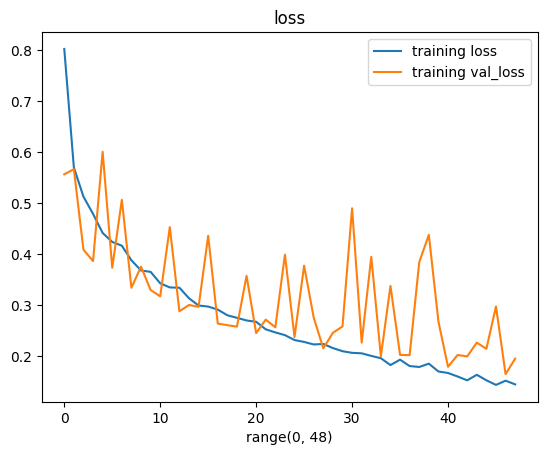

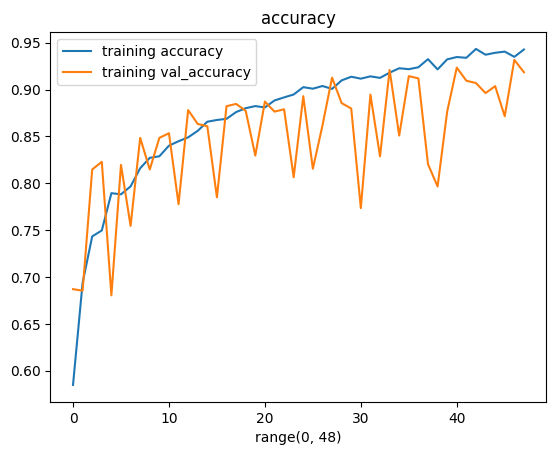

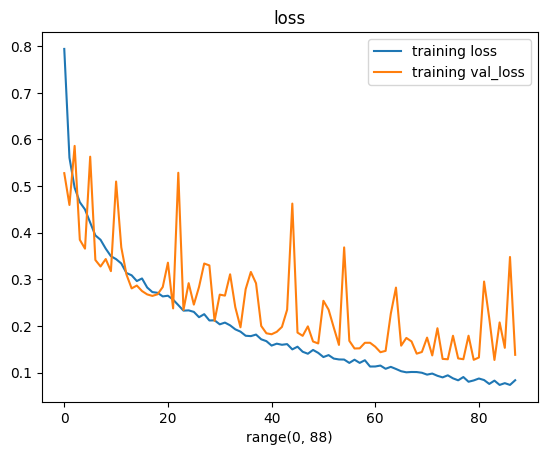

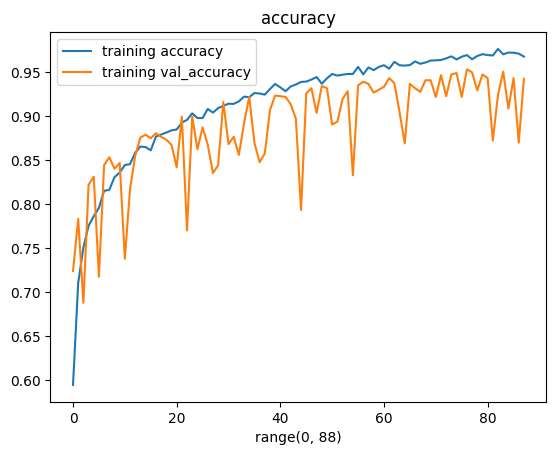

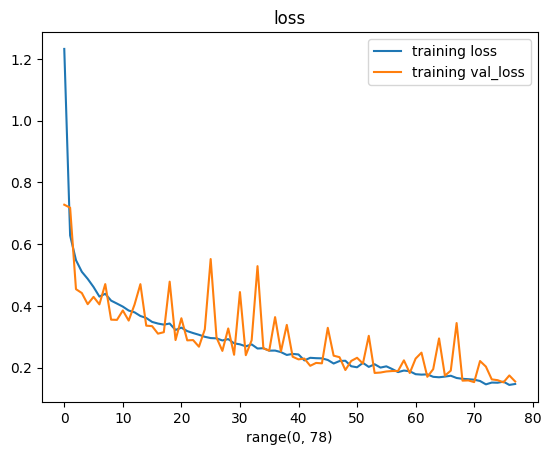

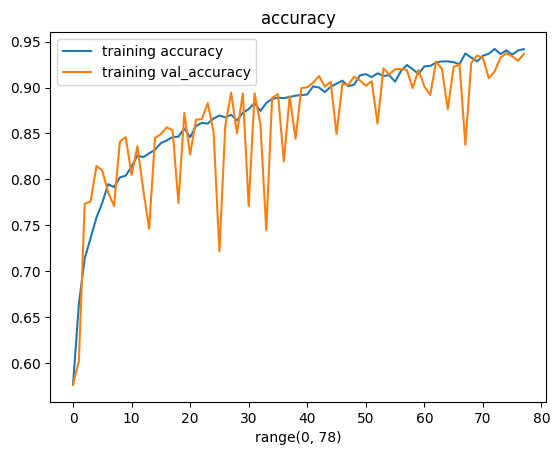

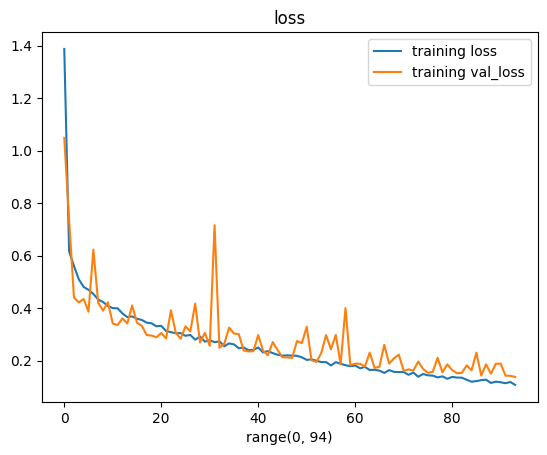

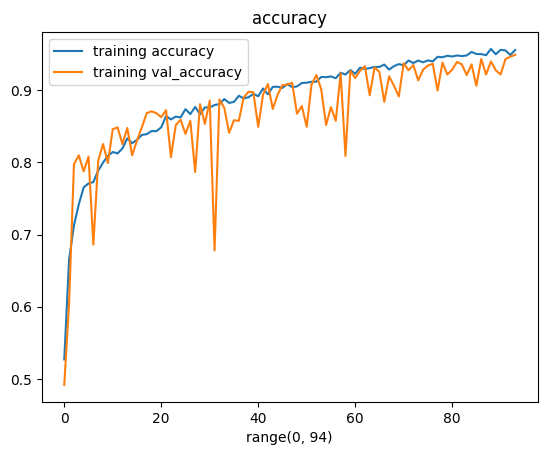

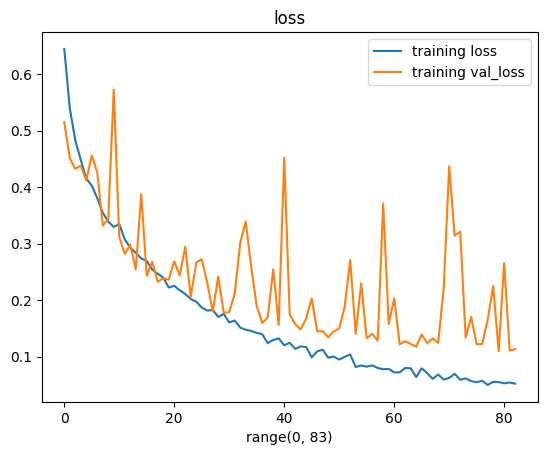

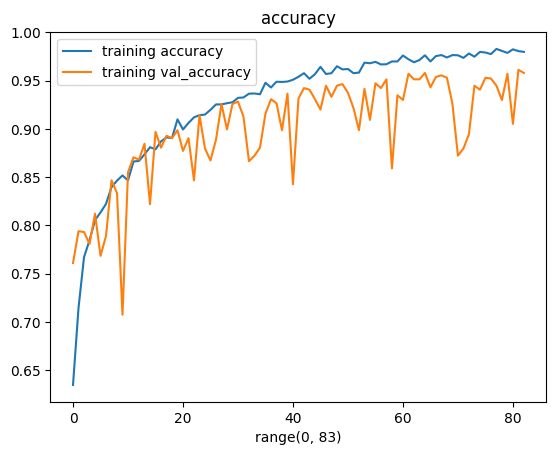

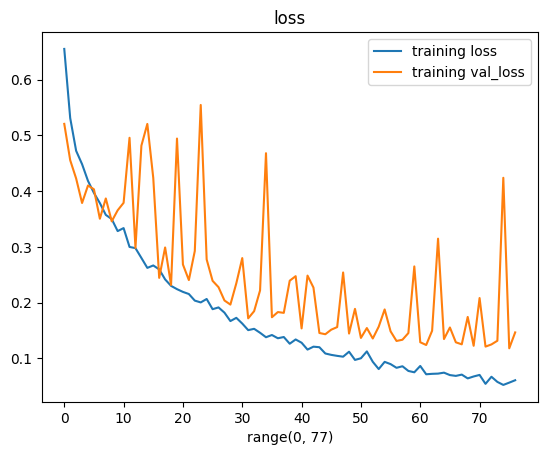

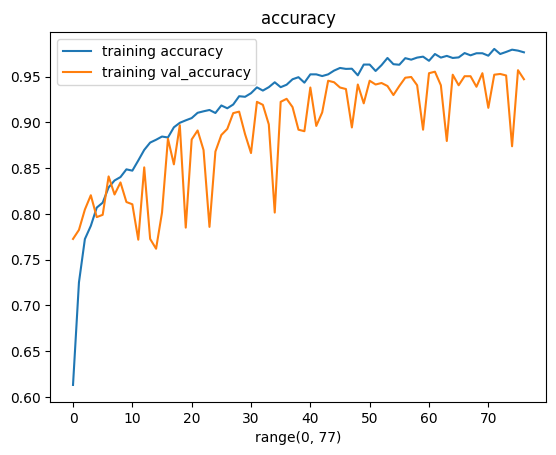

In [ ]:
def plot_history(history, title=""):
    """Eğitim/doğrulama kayıp ve doğruluk eğrilerini iki ayrı figür olarak çizer."""
    epochs = range(len(history.history["loss"]))

    plt.figure()
    plt.plot(epochs, history.history["loss"], label="eğitim kaybı")
    plt.plot(epochs, history.history["val_loss"], label="doğrulama kaybı")
    plt.xlabel("epoch")
    plt.ylabel("kayıp")
    plt.title(f"Kayıp — {title}")
    plt.legend()

    plt.figure()
    plt.plot(epochs, history.history["accuracy"], label="eğitim doğruluğu")
    plt.plot(epochs, history.history["val_accuracy"], label="doğrulama doğruluğu")
    plt.xlabel("epoch")
    plt.ylabel("doğruluk")
    plt.title(f"Doğruluk — {title}")
    plt.legend()
    plt.show()


for name, history in histories.items():
    plot_history(history, title=name)


## 8. Değerlendirme

Test kümesi üzerinde doğruluk, kesinlik, duyarlılık ve F1 skoru hesaplanır.

> **Önceki sürümdeki hata:** metrikler, softmax olasılıklarına `> 0.6` eşiği
> uygulanarak üretilen geçersiz etiketlerle hesaplanıyordu. Bu sürümde softmax
> çıkışı `argmax`, sigmoid çıkışı `0.5` eşiği ile etikete dönüştürülür.


In [ ]:
def evaluate_classifier(model, generator, is_softmax):
    """Test üreteci üzerinde metrikleri hesaplar."""
    probabilities = model.predict(generator, verbose=0)
    if is_softmax:
        y_pred = np.argmax(probabilities, axis=1)
    else:
        y_pred = (probabilities.ravel() >= 0.5).astype(int)
    y_true = generator.classes

    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "precision": precision_score(y_true, y_pred, zero_division=0),
        "recall": recall_score(y_true, y_pred, zero_division=0),
        "f1": f1_score(y_true, y_pred, zero_division=0),
    }


rows = []
for name, model in fitted.items():
    is_softmax = EXPERIMENTS[name]["head"] == "softmax"
    metrics = evaluate_classifier(model, test_cat if is_softmax else test_bin, is_softmax)
    rows.append((name, model.count_params(), metrics))

print(f"{'model':<12}{'parametre':>12}{'doğruluk':>10}{'kesinlik':>10}{'duyarlılık':>12}{'F1':>8}")
print("-" * 64)
for name, params, m in rows:
    print(f"{name:<12}{params:>12,}{m['accuracy']:>10.4f}{m['precision']:>10.4f}"
          f"{m['recall']:>12.4f}{m['f1']:>8.4f}")


## Sonuçlar ve çıkarımlar

* VGG16 gövdesi dondurulduğunda yalnızca başlık eğitildiği için eğitim hızlıdır, ancak
  başlık boyutu (`Dense(6272)`, `Dense(8192)`) gereğinden büyük seçildiğinde
  doğrulama kaybı dalgalanır ve aşırı öğrenme başlar.
* İki katmanlı hafif başlık (`model3`) ile çok geniş tek katman (`model2`) arasında
  belirgin bir fark çıkmamıştır; parametre sayısı açısından hafif başlık tercih edilir.
* Veri artırmalı varyant (`model4`), eğitim–doğrulama eğrileri arasındaki açıklığı
  azaltır; küçük veri kümelerinde beklenen davranıştır.
* InceptionV3 tabanlı `model_in_5_1.h5` (bkz. `03`) bu varyantlardan belirgin şekilde
  daha iyi sonuç verdiği için dağıtımda o model kullanılmıştır.

### Sınırlamalar

* Bölme **kesit düzeyindedir**; aynı hastanın kesitleri eğitim ve test kümelerine
  birlikte düşebilir. Bu, raporlanan doğruluğu iyimser kılar (veri sızıntısı).
  Yayına hazır bir değerlendirme için bölme hasta düzeyinde yapılmalıdır.
* Görüntüler zenginleştirilmiş (fused PET/BT) aksiyel kesitlerdir; sinyal kaynağı
  ayrıştırılmamıştır.
